In [ ]:
# Gym & Fitness Center Membership Analytics
#Student Name: MO SAJID  Addmission NO. : 2026B01010277
# Run from the project root OR from this notebook. The CSV path is resolved automatically.

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def find_dataset():
    candidates = [
        Path("data/12_gym_membership.csv"),
        Path("../data/12_gym_membership.csv"),
        Path("12_gym_membership.csv"),
        Path("../12_gym_membership.csv"),
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        "Dataset not found. Keep 12_gym_membership.csv in the project's data/ folder."
    )

DATA_PATH = find_dataset()
df = pd.read_csv(DATA_PATH)

print("TASK 1 — Load and inspect dataset")
print("Shape:", df.shape)
display(df.head())
display(df.info())

TASK 1 — Load and inspect dataset
Shape: (862, 8)


,Checkin_ID,Member_ID,Membership_Tier,Gender,Checkin_Time,Workout_Duration_Mins,Fitness_Class,Monthly_Fee
0,G00000,M0316,Platinum,Other,2026-05-01 22:00:00,30.0,HIIT,999
1,G00001,M0234,Basic,Male,2025-05-01 07:00:00,71.0,Spin,2499
2,G00002,M0094,Gold,Female,2026-10-14 17:00:00,129.0,Spin,1499
3,G00003,M0204,Gold,Other,2025-10-09 15:00:00,NaN,Spin,1499
4,G00004,M0281,Basic,Male,2025-04-11 09:00:00,107.0,Spin,999


<class 'pandas.DataFrame'>
RangeIndex: 862 entries, 0 to 861
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Checkin_ID             862 non-null    str    
 1   Member_ID              862 non-null    str    
 2   Membership_Tier        862 non-null    str    
 3   Gender                 862 non-null    str    
 4   Checkin_Time           862 non-null    str    
 5   Workout_Duration_Mins  841 non-null    float64
 6   Fitness_Class          707 non-null    str    
 7   Monthly_Fee            862 non-null    int64  
dtypes: float64(1), int64(1), str(6)
memory usage: 54.0 KB


None

In [2]:

# Task 2 — Check missing and duplicate Checkin_ID values
print("\nTASK 2 — Checkin_ID quality")
print("Missing Checkin_ID:", df["Checkin_ID"].isna().sum())
print("Duplicate Checkin_ID rows:", df["Checkin_ID"].duplicated().sum())

# Remove duplicate check-in IDs, keeping the first occurrence
gym_clean = df.drop_duplicates(subset="Checkin_ID", keep="first").copy()
print("Rows after duplicate removal:", len(gym_clean))


TASK 2 — Checkin_ID quality
Missing Checkin_ID: 0
Duplicate Checkin_ID rows: 12
Rows after duplicate removal: 850


In [3]:
print("\nTASK 3 — Clean missing workout duration")
# Task 3 — Clean missing workout duration using median
gym_clean["Workout_Duration_Mins"] = pd.to_numeric(
    gym_clean["Workout_Duration_Mins"], errors="coerce"
)
duration_median = gym_clean["Workout_Duration_Mins"].median()
missing_duration_before = gym_clean["Workout_Duration_Mins"].isna().sum()
gym_clean["Workout_Duration_Mins"] = gym_clean["Workout_Duration_Mins"].fillna(duration_median)
print("Missing workout durations imputed:", missing_duration_before)
print("Median used:", duration_median)


TASK 3 — Clean missing workout duration
Missing workout durations imputed: 21
Median used: 72.0


In [4]:
print("\nTASK 4 — Parse check-in time and derive weekday/hour")
# Task 4 — Parse check-in time and derive weekday/hour
gym_clean["Checkin_Time"] = pd.to_datetime(gym_clean["Checkin_Time"], errors="coerce")
invalid_time_rows = gym_clean["Checkin_Time"].isna().sum()
gym_clean = gym_clean.dropna(subset=["Checkin_Time"]).copy()
gym_clean["Weekday"] = gym_clean["Checkin_Time"].dt.day_name()
gym_clean["Hour"] = gym_clean["Checkin_Time"].dt.hour
gym_clean["Month"] = gym_clean["Checkin_Time"].dt.to_period("M").astype(str)
print("Invalid timestamps removed:", invalid_time_rows)
display(gym_clean[["Checkin_Time", "Weekday", "Hour", "Month"]].head())


TASK 4 — Parse check-in time and derive weekday/hour
Invalid timestamps removed: 0


,Checkin_Time,Weekday,Hour,Month
0,2026-05-01 22:00:00,Friday,22,2026-05
1,2025-05-01 07:00:00,Thursday,7,2025-05
2,2026-10-14 17:00:00,Wednesday,17,2026-10
3,2025-10-09 15:00:00,Thursday,15,2025-10
4,2025-04-11 09:00:00,Friday,9,2025-04


In [5]:
# Task 5 — Total check-ins and average duration
print("\nTASK 5 — Overall check-in metrics")
total_checkins = len(gym_clean)
average_duration = gym_clean["Workout_Duration_Mins"].mean()
print("Total check-ins:", total_checkins)
print("Average workout duration (minutes):", round(average_duration, 2))


TASK 5 — Overall check-in metrics
Total check-ins: 850
Average workout duration (minutes): 72.43


In [6]:
# Task 6 — Compare membership tiers
tier_summary = gym_clean.groupby("Membership_Tier").agg(
    Checkins=("Checkin_ID", "count"),
    Unique_Members=("Member_ID", "nunique"),
    Avg_Duration_Mins=("Workout_Duration_Mins", "mean")
).sort_values("Checkins", ascending=False)
print("\nTASK 6 — Membership tier comparison")
display(tier_summary.round(2))


TASK 6 — Membership tier comparison


,Checkins,Unique_Members,Avg_Duration_Mins
Membership_Tier,,,
Basic,415,242,71.87
Gold,293,212,74.44
Platinum,142,122,69.95


In [7]:
# Task 7 — Peak check-in hours and busiest days
hour_summary = gym_clean["Hour"].value_counts().sort_index()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary = gym_clean["Weekday"].value_counts().reindex(weekday_order, fill_value=0)
print("\nTASK 7 — Peak hours and busiest days")
print("Busiest hour(s):", hour_summary[hour_summary == hour_summary.max()].index.tolist())
print("Busiest day(s):", weekday_summary[weekday_summary == weekday_summary.max()].index.tolist())
display(hour_summary.rename("Checkins").to_frame())
display(weekday_summary.rename("Checkins").to_frame())


TASK 7 — Peak hours and busiest days
Busiest hour(s): [7, 13]
Busiest day(s): ['Saturday']


,Checkins
Hour,
5,46
6,46
7,63
8,44
9,37
10,46
11,43
12,44
13,63


,Checkins
Weekday,
Monday,127
Tuesday,114
Wednesday,126
Thursday,125
Friday,101
Saturday,137
Sunday,120


In [8]:
# Task 8 — Fitness class attendance ranking
class_summary = gym_clean["Fitness_Class"].fillna("Not Specified").value_counts()
print("\nTASK 8 — Fitness class attendance")
display(class_summary.rename("Checkins").to_frame())



TASK 8 — Fitness class attendance


,Checkins
Fitness_Class,
Not Specified,153
Strength,151
Spin,143
Zumba,136
HIIT,135
Yoga,132


In [9]:
# Task 9 — Gender-wise workout duration comparison
gender_summary = gym_clean.groupby("Gender")["Workout_Duration_Mins"].agg(
    ["count", "mean", "median"]
).round(2)
print("\nTASK 9 — Gender-wise workout duration")
display(gender_summary)



TASK 9 — Gender-wise workout duration


,count,mean,median
Gender,,,
Female,296,73.03,72.0
Male,292,73.10,72.0
Other,262,71.02,72.0


In [10]:
# Task 10 — Estimate monthly revenue by membership tier.
# Monthly_Fee is repeated on each check-in row. To avoid multiplying a member's fee
# by their number of visits, estimate revenue using unique Member_ID + Month + Tier.
# If a member has more than one fee in a month/tier, use the mean fee for that group.
member_month_tier = gym_clean.groupby(
    ["Member_ID", "Month", "Membership_Tier"], as_index=False
).agg(Monthly_Fee=("Monthly_Fee", "mean"))
revenue_summary = member_month_tier.groupby(
    ["Month", "Membership_Tier"]
)["Monthly_Fee"].sum().unstack(fill_value=0)
print("\nTASK 10 — Estimated monthly revenue by tier")
display(revenue_summary.round(2))


TASK 10 — Estimated monthly revenue by tier


Membership_Tier,Basic,Gold,Platinum
Month,,,
2025-01,22489.0,21987.0,10994.0
2025-02,25983.0,23983.0,999.0
2025-03,38478.0,20235.0,17491.0
2025-04,30981.0,22485.0,12992.0
2025-05,14990.0,24986.0,6996.0
2025-06,31980.0,13491.0,9993.0
2025-07,31482.0,21488.0,7495.0
2025-08,38479.0,12492.0,9495.0
2025-09,27732.0,19490.0,8494.0


In [11]:
# Task 11 — Low-engagement members: fewer than 2 check-ins per member-month
member_month_visits = gym_clean.groupby(
    ["Member_ID", "Month"]
).size().rename("Visits").reset_index()
low_engagement = member_month_visits[member_month_visits["Visits"] < 2].copy()
print("\nTASK 11 — Low-engagement member-month records")
print("Low-engagement member-month records:", len(low_engagement))
print("Distinct members with at least one low-engagement month:", low_engagement["Member_ID"].nunique())
display(low_engagement.head(10))


TASK 11 — Low-engagement member-month records
Low-engagement member-month records: 761
Distinct members with at least one low-engagement month: 345


,Member_ID,Month,Visits
0,M0001,2026-09,1
1,M0002,2025-03,1
2,M0003,2025-04,1
3,M0003,2025-12,1
4,M0003,2026-07,1
5,M0004,2026-07,1
6,M0005,2025-02,1
7,M0006,2025-01,1
8,M0006,2025-03,1
9,M0006,2025-07,1


In [12]:
# Task 12 — NumPy median, variance, and quartiles
durations = gym_clean["Workout_Duration_Mins"].to_numpy(dtype=float)
np_median = np.median(durations)
np_variance = np.var(durations)  # population variance (ddof=0)
q1, q2, q3 = np.percentile(durations, [25, 50, 75])
print("\nTASK 12 — NumPy statistics")
print(f"Median: {np_median:.2f}")
print(f"Population variance: {np_variance:.2f}")
print(f"Q1: {q1:.2f}, Q2: {q2:.2f}, Q3: {q3:.2f}")


TASK 12 — NumPy statistics
Median: 72.00
Population variance: 974.35
Q1: 47.00, Q2: 72.00, Q3: 98.75


In [13]:
# Task 13 — IQR outlier detection
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = gym_clean[
    (gym_clean["Workout_Duration_Mins"] < lower_bound) |
    (gym_clean["Workout_Duration_Mins"] > upper_bound)
]
print("\nTASK 13 — IQR outliers")
print(f"IQR: {iqr:.2f}; lower bound: {lower_bound:.2f}; upper bound: {upper_bound:.2f}")
print("Outlier rows:", len(outliers))
display(outliers.head())


TASK 13 — IQR outliers
IQR: 51.75; lower bound: -30.62; upper bound: 176.38
Outlier rows: 0


,Checkin_ID,Member_ID,Membership_Tier,Gender,Checkin_Time,Workout_Duration_Mins,Fitness_Class,Monthly_Fee,Weekday,Hour,Month



TASK 14 — Workout duration categories


,Checkins
Workout_Intensity,
Extended,268
Long,251
Moderate,232
Short,99


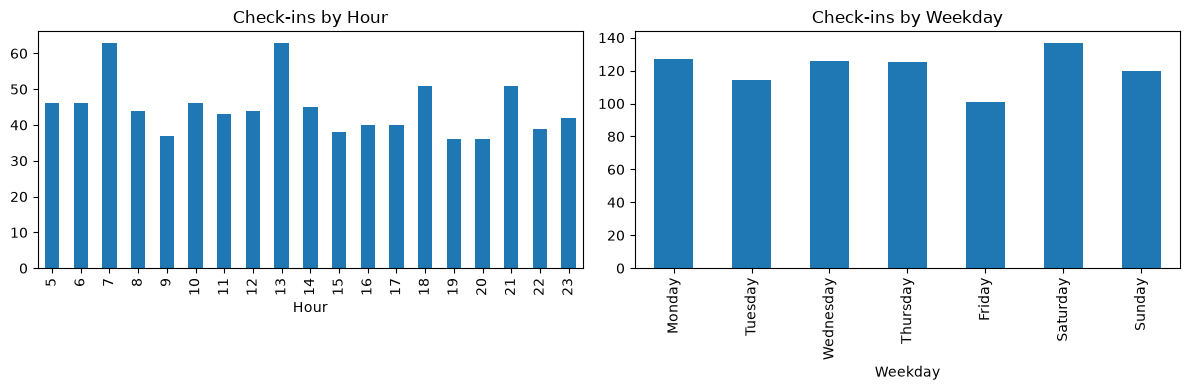

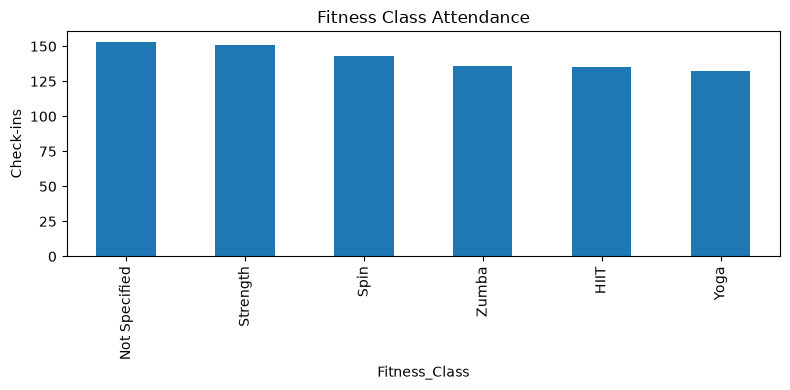

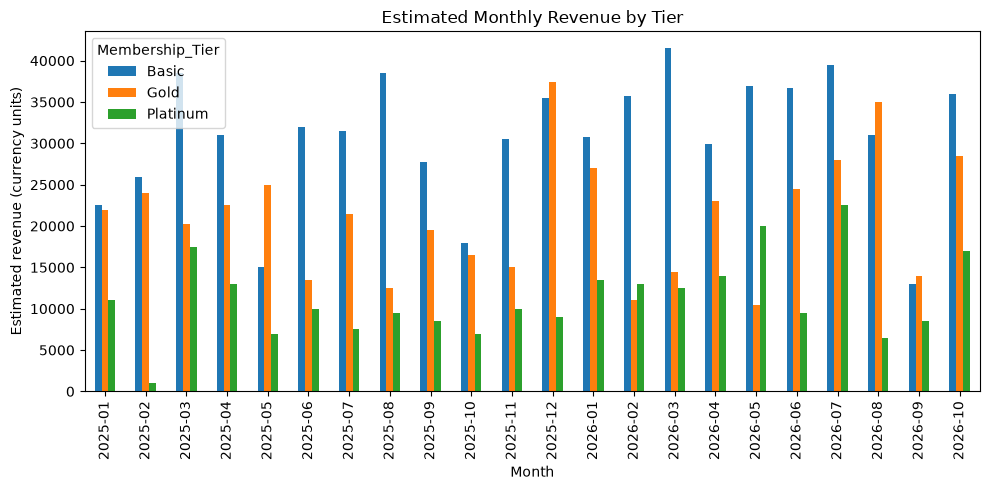

In [14]:
# Task 14 — Workout intensity labels using duration bands
# These are simple project-defined duration categories, not clinical intensity measures.
gym_clean["Workout_Intensity"] = pd.cut(
    gym_clean["Workout_Duration_Mins"],
    bins=[-np.inf, 30, 60, 90, np.inf],
    labels=["Short", "Moderate", "Long", "Extended"]
)
print("\nTASK 14 — Workout duration categories")
display(gym_clean["Workout_Intensity"].value_counts().to_frame("Checkins"))

# Visual summaries
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hour_summary.plot(kind="bar", ax=axes[0], title="Check-ins by Hour")
weekday_summary.plot(kind="bar", ax=axes[1], title="Check-ins by Weekday")
plt.tight_layout()
plt.show()

class_summary.plot(kind="bar", figsize=(8, 4), title="Fitness Class Attendance")
plt.ylabel("Check-ins")
plt.tight_layout()
plt.show()

revenue_summary.plot(kind="bar", figsize=(10, 5), title="Estimated Monthly Revenue by Tier")
plt.ylabel("Estimated revenue (currency units)")
plt.tight_layout()
plt.show()

In [15]:
# Task 15 — Five recommendations
print("\nTASK 15 — Business recommendations")
recommendations = [
    "Schedule more trainer and equipment coverage during the highest check-in hours.",
    "Use Saturday attendance patterns to plan staffing, cleaning, and class capacity.",
    "Promote lower-attendance classes with trial sessions and member feedback.",
    "Contact members with fewer than two visits in a month and offer a simple re-engagement plan.",
    "Review membership-tier pricing and monthly-fee records regularly; revenue here is an estimate."
]
for number, recommendation in enumerate(recommendations, start=1):
    print(f"{number}. {recommendation}")

# Optional: save the cleaned analysis dataset beside the notebook output
output_path = Path("gym_membership_cleaned.csv")
gym_clean.to_csv(output_path, index=False)
print(f"\nCleaned dataset saved to: {output_path.resolve()}")



TASK 15 — Business recommendations
1. Schedule more trainer and equipment coverage during the highest check-in hours.
2. Use Saturday attendance patterns to plan staffing, cleaning, and class capacity.
3. Promote lower-attendance classes with trial sessions and member feedback.
4. Contact members with fewer than two visits in a month and offer a simple re-engagement plan.
5. Review membership-tier pricing and monthly-fee records regularly; revenue here is an estimate.

Cleaned dataset saved to: C:\Users\win\Gym-Fitness-Membership-Analytics\src\gym_membership_cleaned.csv
